# MODELIZACIÓN

## IMPORTAR PAQUETES

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
import janitor
import os
from pathlib import Path
import openpyxl
import sqlalchemy as sa

from sklearn.feature_selection import mutual_info_regression
from sklearn.feature_selection import RFE
from xgboost import XGBRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error

# Desactivar notación científica
pd.set_option('display.float_format', lambda x: '%.3f' % x)
np.set_printoptions(suppress=True)

# Cargar variables de entorno
load_dotenv()

print("✅ Librerías importadas correctamente")

✅ Librerías importadas correctamente


## IMPORTAR LOS DATOS

Cargar los datos

In [54]:
x = pd.read_pickle('../02_datos/03_Entrenamiento/x_preseleccionado.pkl')
y = pd.read_pickle('../02_datos/03_Entrenamiento/y_preseleccionado.pkl')

## MODELIZANDO PARA UN PRODUCTO

In [55]:
x = x.loc[(x.store_id == 'CA_3') & (x.item_id == 'FOODS_3_586')]

Al filtrar x por tienda y producto, x se queda con menos filas, pero sigue conteniendo todas las originales. Con este ajuste filtro y me quedo solo con las filas cuyos índices están en x, de modo que ambos DataFrames tengan las mismas filas.

In [56]:
# Filtrar y para quedarnos solo con las filas de la tienda y producto seleccionados (mismos índices que x)
y = y[y.index.isin(x.index)]


### Modelizar

#### Definiar las variables

In [57]:
var_modelizar = x.columns.to_list()[3:]

#### Definir la validación

Partimos los datos en 3 bloques para predecir los siguientes 8 días. En cada prueba, el train cuenta con más datos que en la anterior para aprender, y el test siempre son los 8 días posteriores.

```text
Días:     1 ............................................ 30
Prueba 1: [train 1-6][test 7-14]
Prueba 2: [train 1-14        ][test 15-22]
Prueba 3: [train 1-22                    ][test 23-30]


In [58]:
time_cv = TimeSeriesSplit(3, test_size = 8)

#### Crear el pipeline y el diccionario de algoritmos, parámetros y valores a testar

Modificar para dejar solo los algoritmos que se quieran testar

Modificar los parámetros

In [59]:
pipe = Pipeline([('algoritmo', HistGradientBoostingRegressor())])

grid = [
    {
        'algoritmo': [HistGradientBoostingRegressor()],
        #'algoritmo__learning_rate': [0.01, 0.025, 0.05, 0.1],
        #'algoritmo__max_iter': [300, 500, 800],
        #'algoritmo__max_depth': [3, 5, 10]  
    }
]

#### Optimizar los hiperparámetros

##### Con random search 

In [60]:
random_search = RandomizedSearchCV(estimator = pipe,
                                   param_distributions = grid,
                                   n_iter = 1,
                                   cv = time_cv,
                                   scoring = 'neg_mean_absolute_error',
                                   verbose = 0,
                                   n_jobs = -1
)

modelo = random_search.fit(x[var_modelizar], y)

c:\Users\phdel\miniconda3\envs\ForecastingRetail\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [61]:
modelo_final = modelo.best_estimator_.fit(x[var_modelizar], y)

c:\Users\phdel\miniconda3\envs\ForecastingRetail\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [62]:
prediccion = modelo_final.predict(x[var_modelizar])

In [65]:
temp = pd.concat([x.date.reset_index(drop=True), 
                  y.reset_index(drop=True), 
                  pd.Series(prediccion, name = 'prediccion')], axis =1
                  )

In [66]:
temp

,date,ventas,prediccion
0,2013-01-16,6,6.874
1,2013-01-17,13,10.557
2,2013-01-18,8,10.718
3,2013-01-19,13,12.685
4,2013-01-20,13,12.100
...,...,...,...
1044,2015-11-26,14,11.935
1045,2015-11-27,10,10.525
1046,2015-11-28,6,7.570
1047,2015-11-29,7,5.967


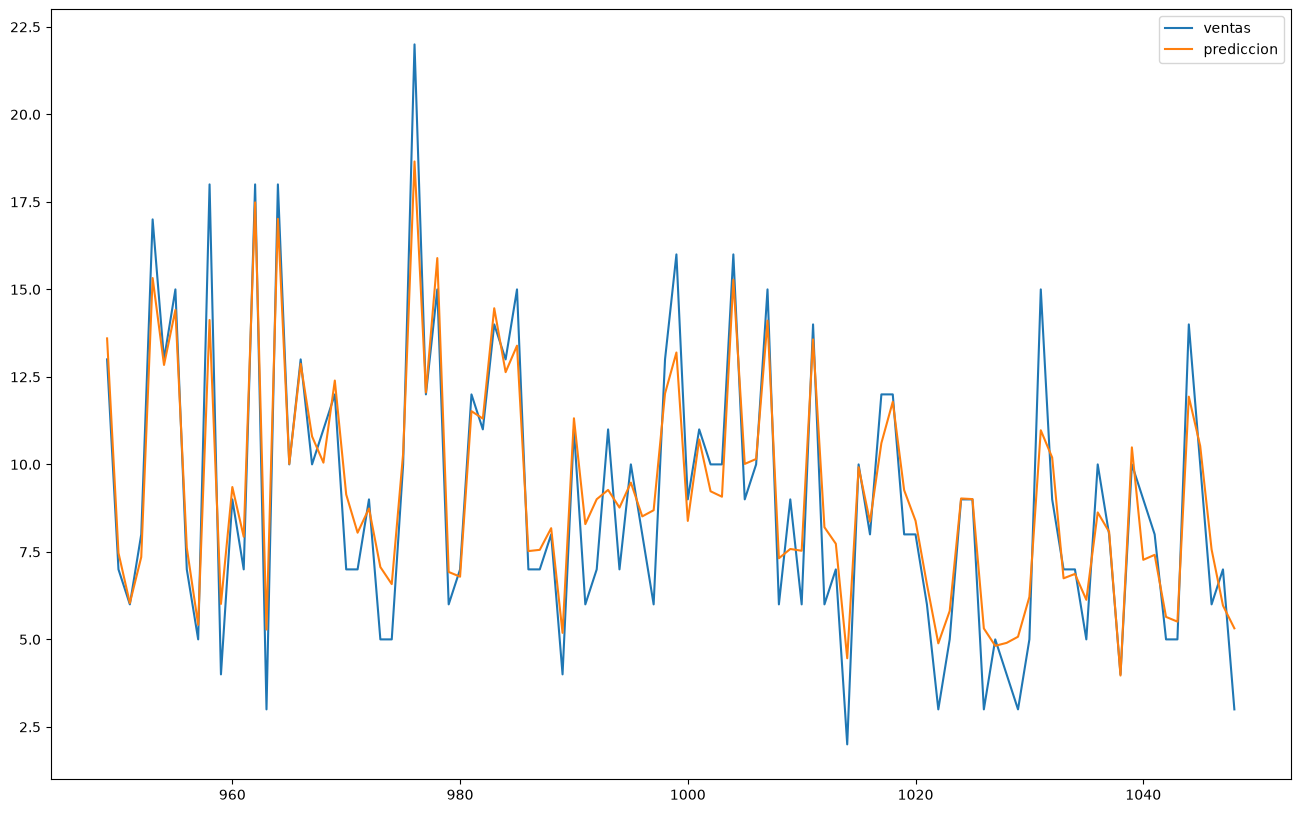

In [68]:
temp.tail(100).plot(figsize= (16,10));

## ESCALAR A TODOS LOS PRODUCTOS

### MODELIZACIÓN